Проверка попадания в детектор
Введите любые координаты (x, y, z). Код автоматически спроецирует их на сферу


Введите x:  0
Введите y:  2
Введите z:  1



Точка на поверхности: X=0.000, Y=1.789, Z=0.894
Попадание! Точка принадлежит ФЭУ с индексом: 2
Координаты центра этого ФЭУ: [0.07713482 1.79487179 0.87891152]


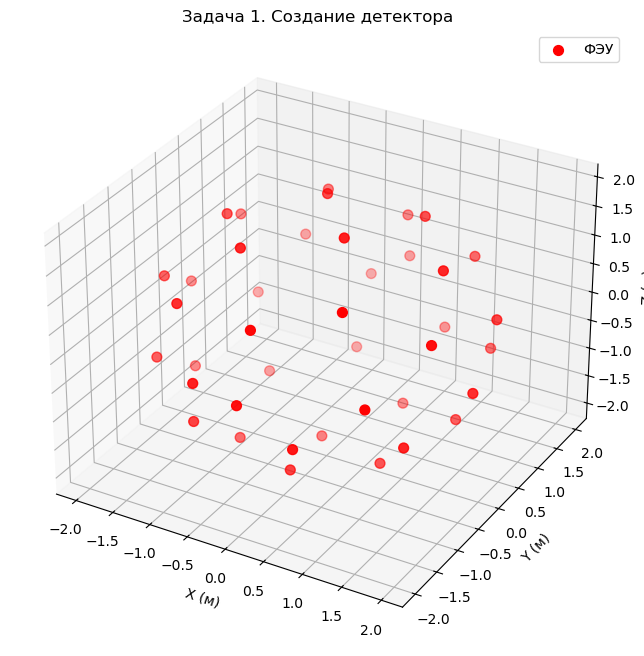

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R # радиус детектора в метрах
        self.N = N # количество ФЭУ
        self.r = r # радиус фотокатода ФЭУ в метрах
        self.a = a # параметр пуассона 

        self.pmt_positions = self.generate_pmt_positions()
        self.pmt_angular_radius = np.arcsin(self.r / self.R)

    # равномерное распределение точек на сфере
    def generate_pmt_positions(self):
        positions = []
        phi = np.pi * (np.sqrt(5.0) - 1.0)  

        for i in range(self.N):
            y = 1.0 - (i / float(self.N - 1)) * 2.0  # y от 1 до -1
            radius_at_y = np.sqrt(1.0 - y * y)
            theta = phi * i

            x = np.cos(theta) * radius_at_y
            z = np.sin(theta) * radius_at_y

            pos = np.array([x, y, z]) * self.R
            positions.append(pos)
            
        return np.array(positions)

    # метод для определения принадлежности точки
    def check_hit_pmt(self, hit_point):
        norm_hit = hit_point / np.linalg.norm(hit_point)
        
        for idx, pmt_pos in enumerate(self.pmt_positions):
            norm_pmt = pmt_pos / self.R
            cos_angle = np.clip(np.dot(norm_hit, norm_pmt), -1.0, 1.0)
            angle = np.arccos(cos_angle)
            
            if angle <= self.pmt_angular_radius:
                return idx # индекс попавшего ФЭУ
                
        return -1

detector = Detector(R=2.0, N=40, r=0.1, a=0.5)

# проверка принадлежности точки
print(f"Проверка попадания в детектор")
print("Введите любые координаты (x, y, z). Код автоматически спроецирует их на сферу")

try:
    user_x = float(input("Введите x: "))
    user_y = float(input("Введите y: "))
    user_z = float(input("Введите z: "))
    
    raw_point = np.array([user_x, user_y, user_z])
    
    if np.linalg.norm(raw_point) == 0:
        print("Ошибка: введены нулевые координаты (центр сферы)")
    else:
        # проецируем на поверхность сферы радиуса R
        surface_point = raw_point / np.linalg.norm(raw_point) * detector.R
        print(f"\nТочка на поверхности: X={surface_point[0]:.3f}, Y={surface_point[1]:.3f}, Z={surface_point[2]:.3f}")
        
        pmt_idx = detector.check_hit_pmt(surface_point)
        
        if pmt_idx != -1:
            print(f"Попадание! Точка принадлежит ФЭУ с индексом: {pmt_idx}")
            print(f"Координаты центра этого ФЭУ: {detector.pmt_positions[pmt_idx]}")
        else:
            print("Промах! Точка не попала ни в один ФЭУ")

except ValueError:
    print("Ошибка: пожалуйста, вводите числовые значения")

# визуализация 
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(detector.pmt_positions[:, 0], 
           detector.pmt_positions[:, 1], 
           detector.pmt_positions[:, 2], 
           color='red', s=50, label='ФЭУ')

ax.set_title("Задача 1. Создание детектора")
ax.set_xlabel("X (м)")
ax.set_ylabel("Y (м)")
ax.set_zlabel("Z (м)")
plt.legend()
plt.show()